# COU07506 - Digital Signal Processing

## Week 3: Convolution, Correlation and Difference Equations

**Registration Number:** 240242444701

**Laboratory:** Lab 1B

## Pre-lab Preparation

### Question (a): Convolution

Given:

x(n) = {1, -1, 2}

h(n) = {2, 1, 0, 1}

Using linear convolution:

y(n) = x(n) * h(n)

The result is:

y(n) = {2, -1, 3, 3, -1, 2}

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

plt.rcParams["figure.figsize"] = (9, 3.5)

In [2]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]

    return y

In [3]:
x = [1, 2, 3, 1]
h = [1, 1, 1]

print("Our convolution:", conv(x, h))
print("NumPy convolution:", np.convolve(x, h))

Our convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]


In [4]:
x = [1, -1, 2]
h = [2, 1, 0, 1]

print("Our convolution:", conv(x, h))
print("NumPy convolution:", np.convolve(x, h))

Our convolution: [ 2. -1.  3.  3. -1.  2.]
NumPy convolution: [ 2 -1  3  3 -1  2]


In [5]:
rng = np.random.default_rng(0)

x_long = rng.standard_normal(2000)
h_long = rng.standard_normal(2000)

start = time.perf_counter()
conv(x_long, h_long)
end = time.perf_counter()
our_time = end - start

start = time.perf_counter()
np.convolve(x_long, h_long)
end = time.perf_counter()
numpy_time = end - start

print("Our convolution time:", our_time, "seconds")
print("NumPy convolution time:", numpy_time, "seconds")

Our convolution time: 3.0246802749998096 seconds
NumPy convolution time: 0.0008179540000128327 seconds


## Task 3.2: Noise Reduction Using Moving Average Filter

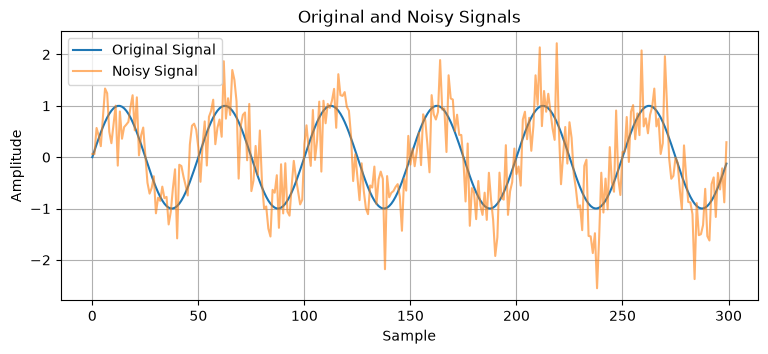

In [6]:
rng = np.random.default_rng(0)

n = np.arange(300)
x_clean = np.sin(2 * np.pi * n / 50)

noise = 0.5 * rng.standard_normal(300)

x_noisy = x_clean + noise

plt.plot(n, x_clean, label="Original Signal")
plt.plot(n, x_noisy, label="Noisy Signal", alpha=0.6)

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("Original and Noisy Signals")
plt.legend()
plt.grid()
plt.show()

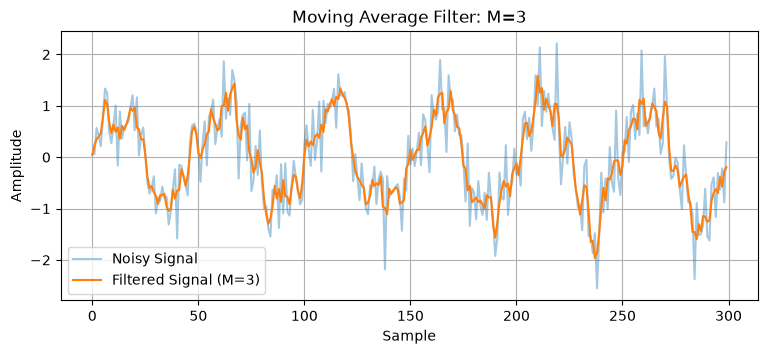

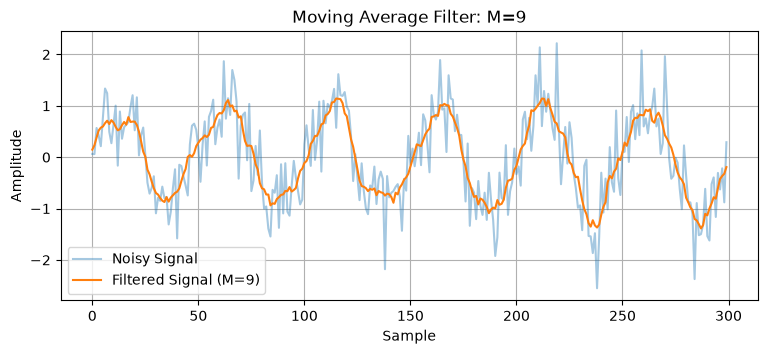

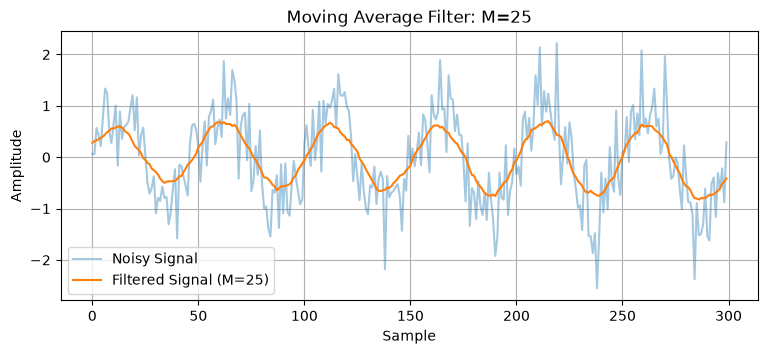

In [7]:
M_values = [3, 9, 25]

for M in M_values:
    h = np.ones(M) / M

    filtered_signal = np.convolve(x_noisy, h, mode="same")

    plt.figure()
    plt.plot(n, x_noisy, label="Noisy Signal", alpha=0.4)
    plt.plot(n, filtered_signal, label=f"Filtered Signal (M={M})")

    plt.xlabel("Sample")
    plt.ylabel("Amplitude")
    plt.title(f"Moving Average Filter: M={M}")
    plt.legend()
    plt.grid()
    plt.show()

### Observation and Discussion

The moving average filter reduces noise in the input signal by averaging consecutive samples.

- For M = 3, a small amount of noise is reduced while most of the original signal shape is preserved.
- For M = 9, noise reduction becomes more noticeable and the output signal becomes smoother.
- For M = 25, more noise is removed, but the original signal becomes more distorted because of excessive smoothing.

Therefore, increasing the filter length improves noise reduction but may also cause signal distortion and loss of important signal details.

## Task 3.3: Testing Linearity and Time Invariance

In [8]:
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

a = 2.0
b = -3.0

print("First signal:", x1)
print("Second signal:", x2)

First signal: [ 0.12573022 -0.13210486  0.64042265  0.10490012 -0.53566937  0.36159505
  1.30400005  0.94708096 -0.70373524 -1.26542147 -0.62327446  0.04132598
 -2.32503077 -0.21879166 -1.24591095 -0.73226735 -0.54425898 -0.31630016
  0.41163054  1.04251337 -0.12853466  1.36646347 -0.66519467  0.35151007
  0.90347018  0.0940123  -0.74349925 -0.92172538 -0.45772583  0.22019512
 -1.00961818 -0.20917557 -0.15922501  0.54084558  0.21465912  0.35537271
 -0.65382861 -0.12961363  0.78397547  1.49343115 -1.25906553  1.51392377
  1.34587542  0.7813114   0.26445563 -0.31392281  1.45802068  1.96025832
  1.80163487  1.31510376]
Second signal: [ 0.35738041 -1.20831863 -0.00445413  0.65647494 -1.28836146  0.39512206
  0.42986369  0.69604272 -1.18411797 -0.66170257 -0.43643525 -1.16980191
  1.73936788 -0.49591073  0.32896963 -0.25857255  1.58347288  1.32036099
  0.63335262 -2.20350988  0.05202897  0.68368619  1.00396158 -0.61790704
  1.82201136 -1.32043097 -0.66152802  0.93504999  0.04905461  2.00239

In [9]:
systems = {
    "x^2": lambda x: x**2,
    "n x(n)": lambda x: np.arange(len(x)) * x,
    "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

for name, T in systems.items():
    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    xd = np.concatenate([np.zeros(5), x1])[:50]
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


In [10]:
linear = np.allclose(
    T(a*x1 + b*x2),
    a*T(x1) + b*T(x2)
)

In [11]:
xd = np.concatenate([np.zeros(5), x1])[:50]

### Observation and Discussion

The simulation produced the following results:

- The x^2 system is nonlinear but time-invariant.
- The n x(n) system is linear but time-varying.
- The moving average system is both linear and time-invariant.

Therefore, the moving average system is the only LTI system among the three tested systems.

The results demonstrate that a system must satisfy both linearity and time-invariance conditions to be classified as an LTI system.

## Task 3.4: Time Delay Estimation Using Cross-Correlation

In [12]:
rng = np.random.default_rng(1)

fs = 1000

x = rng.standard_normal(500)

true_delay = 37

y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]

y = y + 0.5*rng.standard_normal(500)

print("Original signal length:", len(x))
print("Delayed signal length:", len(y))
print("Actual delay:", true_delay, "samples")

Original signal length: 500
Delayed signal length: 500
Actual delay: 37 samples


In [13]:
r = signal.correlate(y, x, mode="full")

lags = signal.correlation_lags(
    len(y), len(x), mode="full"
)

estimated_delay = lags[np.argmax(r)]

print("Estimated delay:", estimated_delay, "samples")

Estimated delay: 37 samples


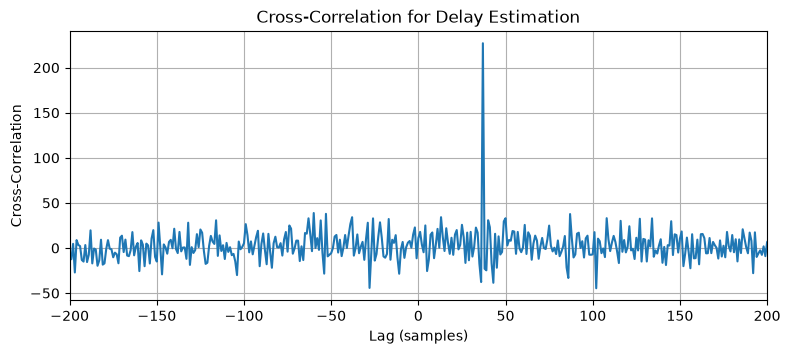

In [14]:
plt.plot(lags, r)

plt.xlim(-200, 200)
plt.xlabel("Lag (samples)")
plt.ylabel("Cross-Correlation")
plt.title("Cross-Correlation for Delay Estimation")
plt.grid()
plt.show()

In [15]:
noise_levels = [0.5, 1, 2, 4]

for noise_level in noise_levels:

    y_test = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]

    y_test = y_test + noise_level * rng.standard_normal(500)

    r_test = signal.correlate(y_test, x, mode="full")

    lags_test = signal.correlation_lags(
        len(y_test), len(x), mode="full"
    )

    estimated = lags_test[np.argmax(r_test)]

    print("Noise level:", noise_level,
          "| Estimated delay:", estimated, "samples")

Noise level: 0.5 | Estimated delay: 37 samples
Noise level: 1 | Estimated delay: 37 samples
Noise level: 2 | Estimated delay: 37 samples
Noise level: 4 | Estimated delay: 37 samples


In [16]:
speed_of_sound = 343

delay_time = estimated_delay / fs

distance = speed_of_sound * delay_time

print("Estimated delay time:", delay_time, "seconds")
print("Estimated distance:", distance, "meters")

Estimated delay time: 0.037 seconds
Estimated distance: 12.690999999999999 meters


### Observation and Discussion

Cross-correlation was used to estimate the time delay between two signals.

The estimated delay was approximately 37 samples, corresponding to 0.037 seconds at a sampling frequency of 1000 Hz.

Using the speed of sound of 343 m/s, the estimated one-way distance was approximately 12.691 meters.

As the noise level increases, the cross-correlation peak may become less distinct, reducing the accuracy of delay estimation.

In [17]:
N = 10

impulse = np.zeros(N)
impulse[0] = 1

print("Impulse input:", impulse)

Impulse input: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [18]:
y_recursive = np.zeros(N)

for n in range(N):

    x_current = impulse[n]

    x_previous = impulse[n-1] if n >= 1 else 0

    y_previous = y_recursive[n-1] if n >= 1 else 0

    y_previous2 = y_recursive[n-2] if n >= 2 else 0

    y_recursive[n] = (
        x_current
        + x_previous
        + 0.75*y_previous
        - 0.125*y_previous2
    )

print("Impulse response using recursion:")
print(y_recursive)

Impulse response using recursion:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [19]:
b = [1, 1]
a = [1, -0.75, 0.125]

y_lfilter = signal.lfilter(b, a, impulse)

print("Impulse response using lfilter:")
print(y_lfilter)

Impulse response using lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [20]:
print("Recursion and lfilter comparison:")
print(np.allclose(y_recursive, y_lfilter))

Recursion and lfilter comparison:
True


In [21]:
n = np.arange(N)

h_closed = 6*(0.5)**n - 5*(0.25)**n

print("Closed-form impulse response:")
print(h_closed)

Closed-form impulse response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [22]:
print("Recursion vs lfilter:",
      np.allclose(y_recursive, y_lfilter))

print("Recursion vs closed-form:",
      np.allclose(y_recursive, h_closed))

print("lfilter vs closed-form:",
      np.allclose(y_lfilter, h_closed))

Recursion vs lfilter: True
Recursion vs closed-form: True
lfilter vs closed-form: True


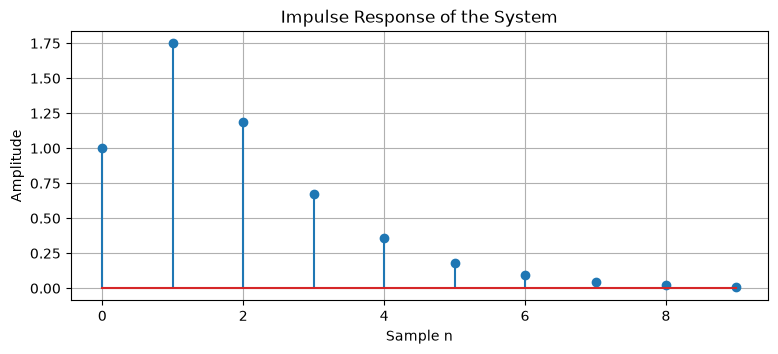

In [23]:
plt.stem(n, y_lfilter)

plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.title("Impulse Response of the System")
plt.grid()
plt.show()

In [24]:
step = np.ones(N)

y_step = signal.lfilter(b, a, step)

print("Step response:")
print(y_step)

Step response:
[1.         2.75       3.9375     4.609375   4.96484375 5.14746094
 5.23999023 5.28656006 5.30992126 5.32162094]


In [25]:
final_value = np.sum(b) / np.sum(a)

print("Final value H(1):", final_value)
print("Last step response sample:", y_step[-1])

Final value H(1): 5.333333333333333
Last step response sample: 5.321620941162109


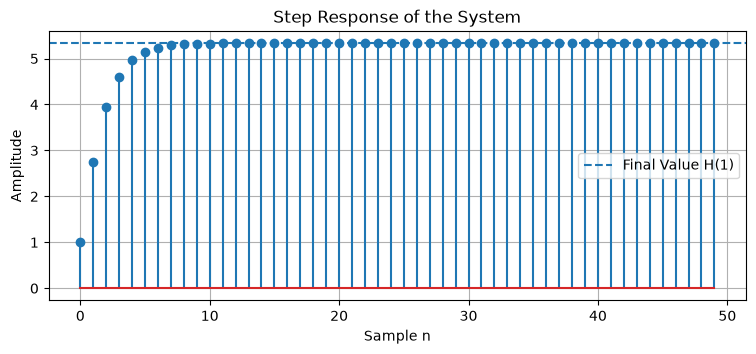

Final theoretical value: 5.333333333333333
Final simulated value: 5.333333333333323


In [26]:
N_step = 50

step_long = np.ones(N_step)

y_step_long = signal.lfilter(b, a, step_long)

plt.stem(np.arange(N_step), y_step_long)

plt.axhline(
    y=np.sum(b)/np.sum(a),
    linestyle="--",
    label="Final Value H(1)"
)

plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.title("Step Response of the System")
plt.legend()
plt.grid()
plt.show()

print("Final theoretical value:", np.sum(b)/np.sum(a))
print("Final simulated value:", y_step_long[-1])

### Step Response Observation

The step response increases gradually and approaches a steady-state value.

The theoretical final value is calculated using:

H(1) = sum(b) / sum(a)

H(1) = 2 / 0.375 = 5.3333

The simulated step response approaches the theoretical value as the number of samples increases. This confirms the steady-state behavior of the system.

### System Classification and Stability

The system is an Infinite Impulse Response (IIR) system because its difference equation contains feedback terms involving previous outputs.

The system is stable because its impulse response decays towards zero. Its poles are 0.5 and 0.25, which are both inside the unit circle.

Therefore, the system is a stable IIR system.

## Checkpoint 3

### 1. System Properties

The following results show the linearity and time-invariance properties of the three tested systems.

In [27]:
systems = {
    "x^2": lambda x: x**2,

    "n x(n)": lambda x: np.arange(len(x)) * x,

    "moving average": lambda x: np.convolve(
        x, np.ones(3)/3, mode="full"
    )[:len(x)]
}

In [28]:
for name, T in systems.items():
    print(name)
    print("T(x1) length:", len(T(x1)))
    print("T(x2) length:", len(T(x2)))
    print("----------------")

x^2
T(x1) length: 50
T(x2) length: 50
----------------
n x(n)
T(x1) length: 50
T(x2) length: 50
----------------
moving average
T(x1) length: 50
T(x2) length: 50
----------------


In [29]:
print("Shape of a:", np.shape(a))
print("Shape of b:", np.shape(b))
print("Shape of x1:", np.shape(x1))
print("Shape of x2:", np.shape(x2))

Shape of a: (3,)
Shape of b: (2,)
Shape of x1: (50,)
Shape of x2: (50,)


In [30]:
a = 2.0
b = -3.0

print("a =", a)
print("b =", b)

print("Shape of a:", np.shape(a))
print("Shape of b:", np.shape(b))

a = 2.0
b = -3.0
Shape of a: ()
Shape of b: ()


In [31]:
for name, T in systems.items():

    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    xd = np.concatenate([np.zeros(5), x1])[:50]
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


In [32]:
print("Recursion vs lfilter:",
      np.allclose(y_recursive, y_lfilter))

print("Recursion vs closed-form:",
      np.allclose(y_recursive, h_closed))

print("lfilter vs closed-form:",
      np.allclose(y_lfilter, h_closed))

Recursion vs lfilter: True
Recursion vs closed-form: True
lfilter vs closed-form: True


## Analysis Questions

### Question 1

The np.convolve() function is faster because it uses optimized, low-level compiled code, while our implementation uses nested Python loops, which have more execution overhead.

For two sequences of lengths L and M, direct linear convolution requires L × M multiplications.

The resulting convolution sequence has a length of:

N = L + M - 1

### Question 2

Among the three tested systems, only the moving average system is Linear Time-Invariant (LTI).

- The x² system is nonlinear but time-invariant.
- The n x(n) system is linear but time-varying.
- The moving average system is both linear and time-invariant.

Therefore, the moving average system is the only LTI system among the three systems tested.

### Question 3

Cross-correlation has several engineering applications in Tanzania.

**1. Water Pipeline Leak Detection**

Cross-correlation can be used to detect and locate water leaks in pipelines. Sensors placed at different points along a water pipe record vibration or acoustic signals produced by a leak. By comparing the signals using cross-correlation, engineers can estimate the time delay and determine the approximate location of the leak.

**2. Radar and Aircraft Detection at Airports**

Cross-correlation can be used in radar systems to detect aircraft and estimate their distance. A radar system compares the transmitted signal with the received reflected signal. The time delay between the signals helps determine the distance of an aircraft from the radar station.

These applications demonstrate how cross-correlation helps engineers estimate time delays and locate signal sources.

### Question 4

The system is an Infinite Impulse Response (IIR) system because its difference equation contains feedback terms involving previous output values.

The system is stable because its poles are 0.5 and 0.25, which are both inside the unit circle.

For a discrete-time system to be stable, all its poles must lie inside the unit circle.

Therefore, the system is a stable IIR system.